# Các nhánh của SVA

In [1]:
import json
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.branches import FrameEncoder, candidate_order, classify_dimension, option_classes, question_part
from sva.config import RESULTS_DIR, TASK_IDS, TASK_META
from sva.data import canon, load_clean
from sva.eval import accuracy, accuracy_ci, correct, ece, load_predictions, load_split, mcnemar
from sva.evidence import hard_vote, linear_pool, log_pool, ordinal_fusion
from sva.models import CLASS_NAMES, ActionClassifier
from sva.perception import PerceptionCache

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})

## 1. Nhánh C · so khớp replay (q9)

In [2]:
dev = json.load(open(RESULTS_DIR / "dev" / "q9_matching.json", encoding="utf-8"))
gold = np.array(dev["gold"])
V = {k: np.array(v) for k, v in dev["variants"].items()}       # [cau, ung vien, (score, Omega, max cos)]
print(len(gold), "câu dev;", len(V), "biến thể; cấu hình chọn:", dev["chosen"])

120 câu dev; 15 biến thể; cấu hình chọn: {'variant': 'clip_vit_l|24|box', 'lam': 0, 'temperature': 0.01, 'accuracy': 80.83333333333333}


### 1.1 Encoder và số frame (dev)

In [3]:
def acc(R, lam=0.0):
    return 100 * ((R[..., 0] - lam * R[..., 1]).argmax(1) == gold).mean()

rows = []
for k, R in V.items():
    enc, n, crop = k.split("|")
    rows.append({"encoder": enc + (" (bỏ viền đen)" if crop == "sq" else ""), "frame/clip": int(n), "accuracy": acc(R)})
grid = pd.DataFrame(rows).pivot(index="encoder", columns="frame/clip", values="accuracy").round(1)
grid

frame/clip,4,12,24
encoder,,,
clip_vit_l,60.8,77.5,80.8
clip_vit_l (bỏ viền đen),63.3,74.2,79.2
dinov2_vitb14 (bỏ viền đen),50.0,65.0,65.0
hsv,45.0,52.5,50.0
siglip (bỏ viền đen),55.0,69.2,73.3


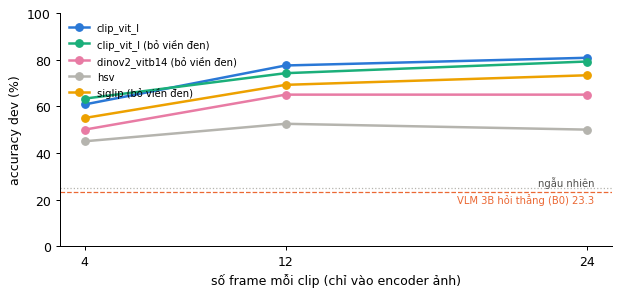

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
colors = {"clip_vit_l": BLUE, "clip_vit_l (bỏ viền đen)": AQUA, "siglip (bỏ viền đen)": "#eda100",
          "dinov2_vitb14 (bỏ viền đen)": "#e87ba4", "hsv": GRAY}
for enc, row in grid.iterrows():
    ax.plot(row.index, row.values, marker="o", lw=2, color=colors[enc], label=enc)
b0_dev = load_predictions("b0_loop_trace", "q9", "dev")
b0_acc = 100 * np.mean([max(r["evidence"][0]["dist"], key=r["evidence"][0]["dist"].get) == r["gold"] for r in b0_dev])
ax.axhline(25, color=GRAY, ls=":", lw=1); ax.text(24.3, 26, "ngẫu nhiên", fontsize=8, color="#52514e", ha="right")
ax.axhline(b0_acc, color=ORANGE, ls="--", lw=1)
ax.text(24.3, b0_acc - 5, f"VLM 3B hỏi thẳng (B0) {b0_acc:.1f}", fontsize=8, color=ORANGE, ha="right")
ax.set_xticks([4, 12, 24]); ax.set_xlabel("số frame mỗi clip (chỉ vào encoder ảnh)"); ax.set_ylabel("accuracy dev (%)")
ax.set_ylim(0, 100); ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### 1.2 Phạt đảo thứ tự thời gian λ

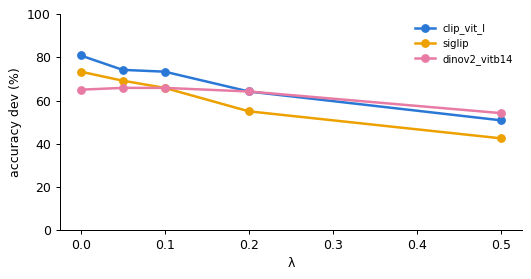

Omega trung bình: ứng viên đúng 0.26, ứng viên sai 0.27


In [5]:
lams = [0, 0.05, 0.1, 0.2, 0.5]
fig, ax = plt.subplots(figsize=(6, 3.2))
for k, c in [("clip_vit_l|24|box", BLUE), ("siglip|24|sq", "#eda100"), ("dinov2_vitb14|24|sq", "#e87ba4")]:
    ax.plot(lams, [acc(V[k], l) for l in lams], marker="o", lw=2, color=c, label=k.split("|")[0])
ax.set_xlabel("λ"); ax.set_ylabel("accuracy dev (%)"); ax.legend(frameon=False, fontsize=8); ax.set_ylim(0, 100)
plt.tight_layout(); plt.show()
R = V["clip_vit_l|24|box"]
om_gold = R[np.arange(len(gold)), gold, 1]
om_wrong = np.array([np.delete(r[:, 1], g) for r, g in zip(R, gold)]).ravel()
print(f"Omega trung bình: ứng viên đúng {om_gold.mean():.2f}, ứng viên sai {om_wrong.mean():.2f}")

### 1.3 Độ tách ứng viên đúng / sai

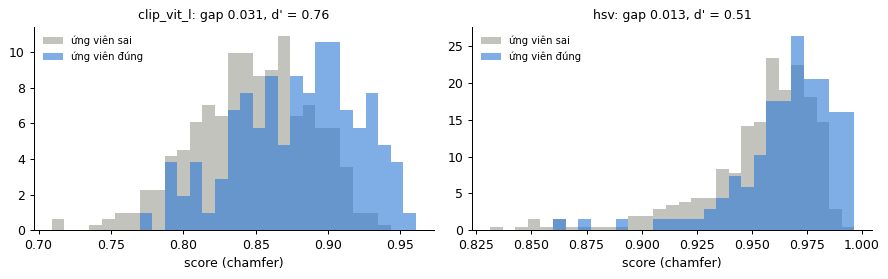

,encoder,gap tuyệt đối,d',accuracy
0,clip_vit_l|24|box,0.031,0.759,80.833
1,hsv|24|box,0.013,0.509,50.000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
rows = []
for ax, k in zip(axes, ["clip_vit_l|24|box", "hsv|24|box"]):
    sc = V[k][..., 0]
    g = sc[np.arange(len(gold)), gold]
    w = np.array([np.delete(x, i) for x, i in zip(sc, gold)]).ravel()
    bins = np.linspace(min(g.min(), w.min()), max(g.max(), w.max()), 30)
    ax.hist(w, bins, color=GRAY, alpha=0.8, density=True, label="ứng viên sai")
    ax.hist(g, bins, color=BLUE, alpha=0.6, density=True, label="ứng viên đúng")
    d = (g.mean() - w.mean()) / np.sqrt((g.var() + w.var()) / 2)
    ax.set_title(f"{k.split('|')[0]}: gap {g.mean() - w.mean():.3f}, d' = {d:.2f}", fontsize=10)
    ax.set_xlabel("score (chamfer)"); ax.legend(frameon=False, fontsize=8)
    rows.append({"encoder": k, "gap tuyệt đối": g.mean() - w.mean(), "d'": d, "accuracy": acc(V[k])})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

### 1.4 Frame gần trùng lặp

In [7]:
rows = []
for k in ["clip_vit_l|24|box", "siglip|24|sq", "dinov2_vitb14|24|sq"]:
    mx = V[k][..., 2] > 0.95
    rows.append({"encoder": k, "cặp đúng có frame cos > 0,95 (%)": 100 * mx[np.arange(len(gold)), gold].mean(),
                 "câu có ứng viên SAI cos > 0,95 (%)": 100 * np.mean([np.delete(x, i).any() for x, i in zip(mx, gold)])})
pd.DataFrame(rows).round(1)

,encoder,"cặp đúng có frame cos > 0,95 (%)","câu có ứng viên SAI cos > 0,95 (%)"
0,clip_vit_l|24|box,61.7,40.8
1,siglip|24|sq,65.8,60.0
2,dinov2_vitb14|24|sq,48.3,31.7


### 1.5 Kênh phụ UniSoccer và bằng chứng VLM

In [8]:
U = np.array(dev["unisoccer"])
print(f"UniSoccer một mình: {100 * (U.argmax(1) == gold).mean():.1f}%  "
      f"(entropy q9 {dev['entropy']['q9']:.2f} vs q10 {dev['entropy']['q10']:.2f}: không lệch miền)")
print("gộp CLIP + w · UniSoccer:", {w: round(a, 1) for w, a in dev["fused"].items()})

T = dev["chosen"]["temperature"]
X = V["clip_vit_l|24|box"][..., 0]
P = np.exp((X - X.max(1, keepdims=True)) / T); P /= P.sum(1, keepdims=True)
trace = {r["index"]: r for r in b0_dev}
rows = []
for tool in ["b0_local", "reorder", "pairwise", "more_frames"]:
    Q = np.array([[next(e for e in trace[i]["evidence"] if e["tool_name"] == tool)["dist"][k] for k in ["O1", "O2", "O3", "O4"]]
                  for i in dev["index"]])
    rows.append({"bằng chứng VLM": tool, "một mình (%)": 100 * (Q.argmax(1) == gold).mean(),
                 "trung bình với so khớp (%)": 100 * (((P + Q) / 2).argmax(1) == gold).mean()})
print(f"so khớp một mình: {100 * (P.argmax(1) == gold).mean():.1f}%")
pd.DataFrame(rows).round(1)

UniSoccer một mình: 58.3%  (entropy q9 0.92 vs q10 1.13: không lệch miền)
gộp CLIP + w · UniSoccer: {'0': 80.8, '0.1': 80.8, '0.25': 79.2, '0.5': 78.3, '1.0': 74.2}
so khớp một mình: 80.8%


,bằng chứng VLM,một mình (%),trung bình với so khớp (%)
0,b0_local,23.3,78.3
1,reorder,21.7,62.5
2,pairwise,20.8,70.8
3,more_frames,23.3,76.7


### 1.6 Ví dụ: replay, ứng viên đúng và ứng viên sai

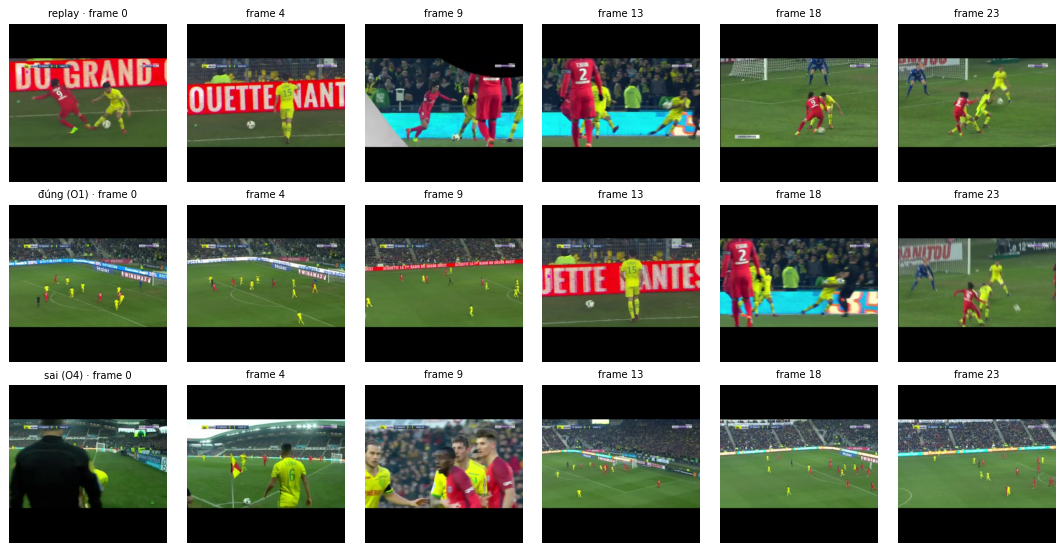

You are given five clips, with the first one being a replay. Which of the following four clips corresponds to the replay?


In [9]:
cache = PerceptionCache()
enc = FrameEncoder("clip_vit_l")
samples = {s.index: s for s in load_split("q9", "dev")}
R = V["clip_vit_l|24|box"]
i = int(np.argmax([r[g, 0] - np.delete(r[:, 0], g).max() for r, g in zip(R, gold)]))   # cau tach ro nhat
s = samples[dev["index"][i]]
order = candidate_order(s)
g = gold[i]
w = int(np.argmax(np.where(np.arange(4) == g, -1, R[i, :, 0])))                          # ung vien sai giong nhat
fig, axes = plt.subplots(3, 6, figsize=(12, 6.2))
for row, (name, path) in enumerate([("replay", s.materials[0]), (f"đúng ({s.option_keys[g]})", s.materials[order[g]]),
                                    (f"sai ({s.option_keys[w]})", s.materials[order[w]])]):
    f, _ = cache.get_frames(path, 24, 336)
    for col, j in enumerate(np.linspace(0, 23, 6).astype(int)):
        axes[row, col].imshow(f[j]); axes[row, col].axis("off")
        axes[row, col].set_title(f"{name} · frame {j}" if col == 0 else f"frame {j}", fontsize=8)
plt.tight_layout(); plt.show()
print(s.question)

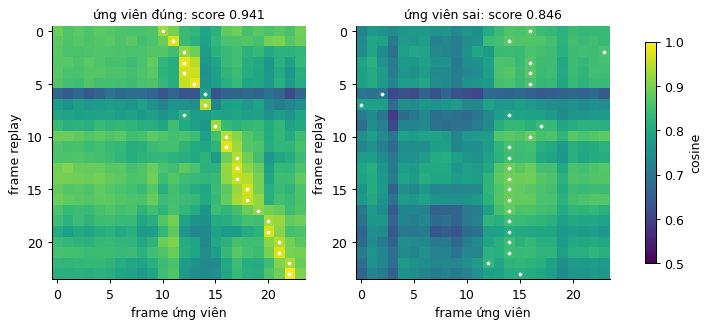

In [10]:
e_r = cache.get_embedding(s.materials[0], 24, 336, enc).astype(np.float32)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, k) in zip(axes, [("đúng", g), ("sai", w)]):
    e_u = cache.get_embedding(s.materials[order[k]], 24, 336, enc).astype(np.float32)
    S = e_r @ e_u.T
    im = ax.imshow(S, vmin=0.5, vmax=1, cmap="viridis")
    ax.plot(S.argmax(1), np.arange(24), "w.", ms=4)
    ax.set_title(f"ứng viên {name}: score {S.max(1).mean():.3f}", fontsize=10)
    ax.set_xlabel("frame ứng viên"); ax.set_ylabel("frame replay")
fig.colorbar(im, ax=axes, shrink=0.8, label="cosine")
plt.show()

### 1.7 Kết quả test

In [11]:
systems = {"B0 (Qwen 3B)": "b0_local", "B0 + vòng lặp": "b0_loop", "B1 (SoccerAgent, 3B)": "b1_vanilla",
           "Gemini hỏi thẳng": "b0_api", "SVA": "sva"}
P_test = {name: load_predictions(sys_, "q9", "test") for name, sys_ in systems.items()}
rows = []
for name, recs in P_test.items():
    lo, hi = accuracy_ci(recs)
    m = mcnemar(recs, P_test["SVA"]) if name != "SVA" else {}
    rows.append({"hệ": name, "n": len(recs), "accuracy": 100 * accuracy(recs), "95% CI": f"{100 * lo:.1f}–{100 * hi:.1f}",
                 "ECE": ece(recs), "hệ này sai, SVA đúng": m.get("b"), "hệ này đúng, SVA sai": m.get("c"),
                 "p (McNemar)": m.get("p_value")})
pd.DataFrame(rows).set_index("hệ").round(4)

,n,accuracy,95% CI,ECE,"hệ này sai, SVA đúng","hệ này đúng, SVA sai",p (McNemar)
hệ,,,,,,,
B0 (Qwen 3B),280,27.5000,22.6–33.0,0.1448,162.0,18.0,0.0
B0 + vòng lặp,280,25.0000,20.3–30.4,0.1940,168.0,17.0,0.0
"B1 (SoccerAgent, 3B)",280,25.7143,20.9–31.1,0.3528,164.0,15.0,0.0
Gemini hỏi thẳng,280,32.5000,27.3–38.2,0.2516,148.0,18.0,0.0
SVA,280,78.9286,73.8–83.3,0.0493,NaN,NaN,NaN


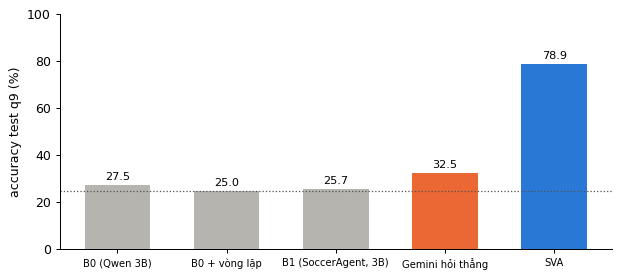

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(P_test)
vals = [100 * accuracy(P_test[n]) for n in names]
ax.bar(range(len(names)), vals, 0.6, color=[GRAY, GRAY, GRAY, ORANGE, BLUE])
for i, v in enumerate(vals):
    ax.text(i, v + 2, f"{v:.1f}", ha="center", fontsize=9)
ax.axhline(25, color="#52514e", ls=":", lw=1)
ax.set_xticks(range(len(names)), names, fontsize=8); ax.set_ylabel("accuracy test q9 (%)"); ax.set_ylim(0, 100)
plt.tight_layout(); plt.show()

## 2. Nhánh C · gộp nhiều góc quay (q14)

In [13]:
dev = json.load(open(RESULTS_DIR / "dev" / "q14_multiview.json", encoding="utf-8"))["rows"]
samples = load_clean("q14")
print(len(samples), "câu q14;", len(dev), "câu dev;", Counter(len(s.materials) for s in samples), "(số góc quay)")

276 câu q14; 84 câu dev; Counter({2: 203, 3: 64, 4: 9}) (số góc quay)


### 2.1 Chiều được hỏi và độ lệch nhãn

In [14]:
rows = []
for s in samples:
    rows.append({"chiều": classify_dimension(s), "đáp án": canon(s.option_texts[s.gold_key])})   # "St. tackling" = "standing tackling"
df = pd.DataFrame(rows)
tab = df.groupby("chiều")["đáp án"].agg(số_câu="size", nhãn_đúng_phổ_biến=lambda x: x.value_counts().index[0],
                                       tỷ_lệ=lambda x: round(100 * x.value_counts().iloc[0] / len(x), 1))
tab.sort_values("số_câu", ascending=False)

,số_câu,nhãn_đúng_phổ_biến,tỷ_lệ
chiều,,,
bodypart,42,under body,69.0
offence,38,offence,100.0
contact,32,with contact,100.0
multiple,30,no,93.3
handball,29,no,100.0
try_to_play,26,yes,84.6
action,25,standing tackling,68.0
severity,24,yellow card,54.2
touch_ball,16,no,93.8


In [15]:
yn = df.assign(q=[question_part(s.question) for s in samples])
yn = yn[yn["chiều"].isin(["handball", "multiple", "touch_ball", "try_to_play"])]
pd.set_option("display.max_colwidth", 80)
yn.groupby("chiều")["q"].apply(lambda x: " | ".join(sorted(set(x)))).to_frame("các cách hỏi")

,các cách hỏi
chiều,
handball,Did the foul occur due to a handball? | Did the offence involve deliberate h...
multiple,Are multiple offences being committed here? | Are multiple rule violations o...
touch_ball,Did the fouling player touch the ball? | Did the offender make contact with ...
try_to_play,Did the player attempt to intercept the ball? | Did the player attempt to pl...


### 2.2 Các cách gộp (dev)

In [16]:
def variants(r):
    v, q, hol = r["views"], r["quality"], r["holistic"]
    out = {"B0 (cả mẫu 1 prompt)": hol, "chỉ góc 1 (camera chính)": v[0], "chỉ góc 2 (thường cận cảnh)": v[1],
           "bỏ phiếu nhãn cứng (SoccerAgent)": hard_vote(v), "linear pool": linear_pool(v),
           "log pool (SVA)": log_pool(v), "log pool + độ rõ": log_pool(v, q),
           "B0 + log pool": linear_pool([hol, log_pool(v)])}
    if r["scale"]:
        out["thang thứ tự"] = ordinal_fusion(v, r["scale"])
    return out

def score(dist, gold):
    top = max(dist.values())
    best = [k for k, p in dist.items() if abs(p - top) < 1e-9]
    return (gold in best) / len(best)          # hoa phieu: tinh dung 1 phan

res = []
for r in dev:
    for name, d in variants(r).items():
        res.append({"cách": name, "chiều": r["dim"], "đúng": score(d, r["gold"])})
res = pd.DataFrame(res)
order = list(variants(dev[0]))
tab = res.pivot_table(index="cách", columns="chiều", values="đúng", aggfunc="mean") * 100
tab.insert(0, "TẤT CẢ", res.groupby("cách")["đúng"].mean() * 100)
tab.loc[order].round(1)

chiều,TẤT CẢ,action,bodypart,contact,handball,multiple,offence,severity,touch_ball,try_to_play,upper_bodypart
cách,,,,,,,,,,,
B0 (cả mẫu 1 prompt),52.4,30.0,36.4,100.0,40.0,71.4,91.7,30.8,0.0,80.0,100.0
chỉ góc 1 (camera chính),63.1,30.0,36.4,85.7,100.0,85.7,91.7,38.5,28.6,80.0,100.0
chỉ góc 2 (thường cận cảnh),57.1,40.0,27.3,100.0,50.0,100.0,100.0,30.8,0.0,80.0,100.0
bỏ phiếu nhãn cứng (SoccerAgent),60.7,35.0,36.4,92.9,85.0,92.9,91.7,34.6,7.1,80.0,100.0
linear pool,63.1,30.0,36.4,100.0,90.0,100.0,91.7,38.5,14.3,80.0,100.0
log pool (SVA),63.1,30.0,36.4,100.0,90.0,100.0,91.7,38.5,14.3,80.0,100.0
log pool + độ rõ,63.1,30.0,36.4,100.0,90.0,100.0,91.7,38.5,14.3,80.0,100.0
B0 + log pool,57.1,30.0,36.4,100.0,70.0,71.4,100.0,30.8,0.0,80.0,100.0


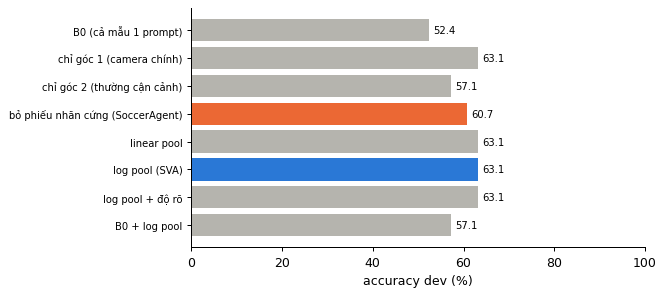

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
t = tab.loc[order, "TẤT CẢ"].drop("thang thứ tự", errors="ignore")
colors = [BLUE if n == "log pool (SVA)" else ORANGE if "bỏ phiếu" in n else GRAY for n in t.index]
ax.barh(range(len(t)), t.values, color=colors)
for i, v in enumerate(t.values):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=8)
ax.set_yticks(range(len(t)), t.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("accuracy dev (%)"); ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

### 2.3 Hòa phiếu và độ rõ tự đánh giá

câu 2 góc: 62; hai góc chọn khác nhau → bỏ phiếu hòa 1–1: 21%
trên các câu hòa đó: log pool đúng 54%, bỏ phiếu (chia đều) 38%


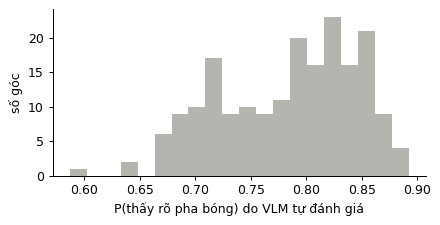

In [18]:
two = [r for r in dev if len(r["views"]) == 2]
disagree = [len({max(d, key=d.get) for d in r["views"]}) > 1 for r in two]
print(f"câu 2 góc: {len(two)}; hai góc chọn khác nhau → bỏ phiếu hòa 1–1: {100 * np.mean(disagree):.0f}%")
sub = [r for r, d in zip(two, disagree) if d]
print(f"trên các câu hòa đó: log pool đúng {100 * np.mean([score(log_pool(r['views']), r['gold']) for r in sub]):.0f}%, "
      f"bỏ phiếu (chia đều) {100 * np.mean([score(hard_vote(r['views']), r['gold']) for r in sub]):.0f}%")
q = np.array([x for r in dev for x in r["quality"]])
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.hist(q, bins=20, color=GRAY); ax.set_xlabel("P(thấy rõ pha bóng) do VLM tự đánh giá"); ax.set_ylabel("số góc")
plt.tight_layout(); plt.show()

### 2.4 Mốc không nhìn video

In [19]:
def prior_pick(train, s):
    c = Counter(canon(x.option_texts[x.gold_key]) for x in train if classify_dimension(x) == classify_dimension(s))
    return max(s.option_keys, key=lambda k: c[canon(s.option_texts[k])])

dev_s, test_s = load_split("q14", "dev"), load_split("q14", "test")
loo = np.mean([prior_pick([x for x in dev_s if x.index != s.index], s) == s.gold_key for s in dev_s])
prior_test = [{"index": s.index, "gold": s.gold_key, "pred": prior_pick(dev_s, s), "n_options": s.n_options} for s in test_s]
print(f"chọn nhãn phổ biến nhất của chiều đó: dev (leave-one-out) {100 * loo:.1f}%, "
      f"test (đếm trên dev) {100 * accuracy(prior_test):.1f}%")

chọn nhãn phổ biến nhất của chiều đó: dev (leave-one-out) 82.1%, test (đếm trên dev) 87.0%


### 2.5 Ví dụ: hai góc bất đồng

How serious was the foul committed?
{'O1': 'Yellow card or red card', 'O2': 'No card or yellow card', 'O3': 'Red card', 'O4': 'Yellow card'} | đáp án: O4
góc 1 (Main camera center): {'O1': 0.26, 'O2': 0.29, 'O3': 0.1, 'O4': 0.35}
góc 2 (Close-up player or field referee): {'O1': 0.31, 'O2': 0.29, 'O3': 0.1, 'O4': 0.3}
bỏ phiếu: {'O1': 0.5, 'O2': 0.0, 'O3': 0.0, 'O4': 0.5} | log pool: {'O1': 0.29, 'O2': 0.29, 'O3': 0.1, 'O4': 0.33}


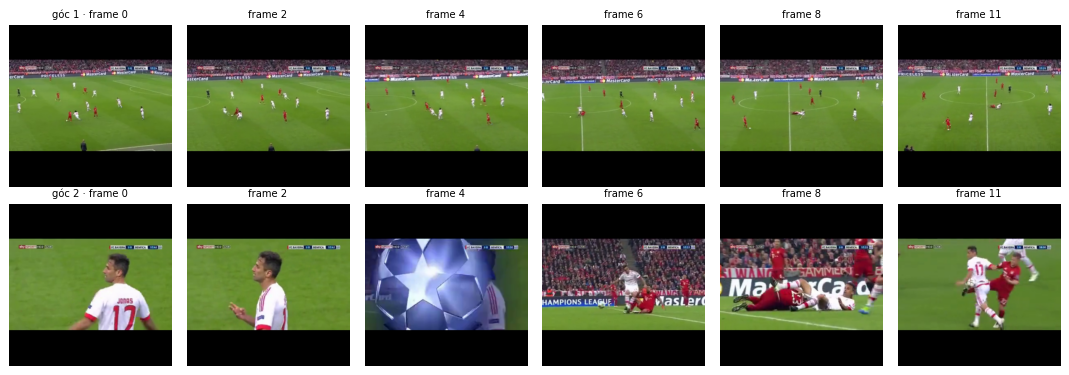

In [20]:
cache = PerceptionCache()
by_idx = {s.index: s for s in dev_s}
r = next(r for r in two if len({max(d, key=d.get) for d in r["views"]}) > 1
         and max(log_pool(r["views"]), key=log_pool(r["views"]).get) == r["gold"])
s = by_idx[r["index"]]
print(question_part(s.question)); print({k: s.option_texts[k] for k in s.option_keys}, "| đáp án:", s.gold_key)
for v, (cam, d) in enumerate(zip(r["cameras"], r["views"])):
    print(f"góc {v + 1} ({cam}):", {k: round(p, 2) for k, p in d.items()})
print("bỏ phiếu:", {k: round(p, 2) for k, p in hard_vote(r["views"]).items()},
      "| log pool:", {k: round(p, 2) for k, p in log_pool(r["views"]).items()})
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for v, path in enumerate(s.materials[:2]):
    f, _ = cache.get_frames(path, 12, 336)
    for c, j in enumerate(np.linspace(0, 11, 6).astype(int)):
        axes[v, c].imshow(f[j]); axes[v, c].axis("off")
        axes[v, c].set_title(f"góc {v + 1} · frame {j}" if c == 0 else f"frame {j}", fontsize=8)
plt.tight_layout(); plt.show()

### 2.6 Kết quả test

In [21]:
systems = {"B0 (Qwen 3B)": "b0_local", "B0 + vòng lặp": "b0_loop", "B1 (SoccerAgent, 3B)": "b1_vanilla",
           "Gemini hỏi thẳng": "b0_api", "SVA": "sva"}
P = {name: load_predictions(sys_, "q14", "test") for name, sys_ in systems.items()}
P["không nhìn video (mốc)"] = prior_test
rows = []
for name, recs in P.items():
    lo, hi = accuracy_ci(recs)
    m = mcnemar(recs, P["SVA"]) if name != "SVA" else {}
    rows.append({"hệ": name, "n": len(recs), "accuracy": 100 * accuracy(recs), "95% CI": f"{100 * lo:.1f}–{100 * hi:.1f}",
                 "hệ này sai, SVA đúng": m.get("b"), "hệ này đúng, SVA sai": m.get("c"), "p (McNemar)": m.get("p_value")})
pd.DataFrame(rows).set_index("hệ").round(4)

,n,accuracy,95% CI,"hệ này sai, SVA đúng","hệ này đúng, SVA sai",p (McNemar)
hệ,,,,,,
B0 (Qwen 3B),192,56.7708,49.7–63.6,22.0,15.0,0.3239
B0 + vòng lặp,192,57.2917,50.2–64.1,22.0,16.0,0.4173
"B1 (SoccerAgent, 3B)",192,45.3125,38.4–52.4,55.0,26.0,0.0019
Gemini hỏi thẳng,192,79.1667,72.9–84.3,13.0,49.0,0.0000
SVA,192,60.4167,53.4–67.1,NaN,NaN,NaN
không nhìn video (mốc),192,86.9792,81.5–91.0,14.0,65.0,0.0000


In [22]:
dim = {s.index: classify_dimension(s) for s in test_s}
per = pd.DataFrame([{"hệ": n, "chiều": dim[r["index"]], "đúng": correct(r)} for n, recs in P.items() for r in recs])
t = per.pivot_table(index="hệ", columns="chiều", values="đúng", aggfunc="mean") * 100
t.loc["(số câu)"] = per[per["hệ"] == "SVA"].groupby("chiều").size()
t.round(1)

chiều,action,bodypart,contact,handball,multiple,offence,severity,touch_ball,try_to_play,upper_bodypart
hệ,,,,,,,,,,
B0 (Qwen 3B),46.7,25.8,100.0,52.6,47.8,84.6,54.5,11.1,61.9,50.0
B0 + vòng lặp,40.0,25.8,100.0,52.6,47.8,92.3,54.5,11.1,66.7,41.7
"B1 (SoccerAgent, 3B)",20.0,48.4,52.0,68.4,43.5,53.8,18.2,66.7,33.3,33.3
Gemini hỏi thẳng,60.0,64.5,100.0,78.9,91.3,92.3,72.7,44.4,76.2,83.3
SVA,40.0,29.0,96.0,78.9,69.6,88.5,45.5,11.1,61.9,33.3
không nhìn video (mốc),73.3,71.0,100.0,100.0,91.3,100.0,45.5,100.0,81.0,100.0
(số câu),15.0,31.0,25.0,19.0,23.0,26.0,11.0,9.0,21.0,12.0


## 3. Nhánh A (q10, q11)

In [23]:
dev = json.load(open(RESULTS_DIR / "dev" / "branch_a.json", encoding="utf-8"))
pd.Series(dev["accuracy"]).round(1).to_frame("accuracy dev")

,accuracy dev
q10 b0,33.3
q10 action,88.0
q10 b0 + action (trung binh),88.7
q10 b0 x action (log pool),88.7
q11 b0,29.0
q11 event,75.7
q11 clip,36.7
q11 b0 + event (trung binh),72.3
q11 b0 x event (log pool),72.0
q11 b0 + clip (trung binh),38.0


### 3.1 q10: phân phối (SVA) so với chuỗi chữ (B1)

In [24]:
cls = ActionClassifier()
test10 = {s.index: s for s in load_split("q10", "test")}
b1 = {r["index"]: r for r in load_predictions("b1_vanilla", "q10", "test")}
sva = {r["index"]: r for r in load_predictions("sva", "q10", "test")}
rows = []
for i, s in test10.items():
    p = cls.probs(s.materials[0])
    top = max(CLASS_NAMES, key=p.get)
    rows.append({"top-1 của UniSoccer nằm trong phương án": any(top == CLASS_NAMES[c] for c in option_classes(s)),
                 "SVA đúng": correct(sva[i]), "B1 đúng": correct(b1[i])})
df = pd.DataFrame(rows)
print(f"top-1 của bộ phân loại nằm ngoài 4 phương án ở {100 * (1 - df.iloc[:, 0].mean()):.0f}% câu")
(df.groupby("top-1 của UniSoccer nằm trong phương án")[["SVA đúng", "B1 đúng"]].mean() * 100).round(1)

top-1 của bộ phân loại nằm ngoài 4 phương án ở 30% câu


,SVA đúng,B1 đúng
top-1 của UniSoccer nằm trong phương án,,
False,75.8,39.1
True,91.9,89.5


### 3.2 q11: ví dụ khớp sự kiện

In [25]:
test11 = {s.index: s for s in load_split("q11", "test")}
recs11 = load_predictions("sva", "q11", "test")
r = next(r for r in recs11 if correct(r) and r["confidence"] > 0.5)
s = test11[r["index"]]
print("đáp án:", s.gold_key, "| bằng chứng:", r["evidence"][0]["raw_observation"])
for k in s.option_keys:
    print(f"{k} ({r['dist'][k]:.2f}): {s.option_texts[k]}")

đáp án: O1 | bằng chứng: video: foul with no card 0.40, clearance 0.24, shot off target 0.15
O1 (0.77): [PLAYER] ([TEAM]) fouls an opponent. At least that's what referee Halil Umut Meler signals.
O2 (0.06): Goal! A rebound wrong foots everyone except [PLAYER] ([TEAM]), and he slams the ball into the open net from close range. 2:0.
O3 (0.07): The [TEAM] players keep the ball and are exchanging a combination of passes. They are waiting for gaps in the defence to open up.
O4 (0.10): The referee shows the yellow card to [PLAYER] ([TEAM]).


## 4. SVA trên 6 task (test)

In [26]:
systems = {"B0": "b0_local", "B0 + vòng lặp": "b0_loop", "B1 (SoccerAgent)": "b1_vanilla", "Gemini hỏi thẳng": "b0_api",
           "SVA": "sva"}
P = {n: {t: load_predictions(s, t, "test") for t in TASK_IDS} for n, s in systems.items()}
tab = pd.DataFrame({n: {t: 100 * accuracy(P[n][t]) for t in TASK_IDS} for n in systems}).T
tab.columns = [f"{t} ({TASK_META[t]['paper_id']})" for t in TASK_IDS]
tab["trung bình"] = tab.mean(axis=1)
tab.round(1)

,q8 (Q7),q9 (Q8),q10 (Q9),q11 (Q10),q13 (Q12),q14 (Q13),trung bình
B0,45.4,27.5,36.1,31.3,45.9,56.8,40.5
B0 + vòng lặp,52.5,25.0,37.4,37.9,46.1,57.3,42.7
B1 (SoccerAgent),45.0,25.7,74.6,31.4,46.3,45.3,44.7
Gemini hỏi thẳng,68.9,32.5,64.4,70.1,48.8,79.2,60.7
SVA,58.9,78.9,87.1,74.3,46.5,60.4,67.7


In [27]:
rows = []
for t in TASK_IDS:
    for other in ["B1 (SoccerAgent)", "B0", "Gemini hỏi thẳng"]:
        m = mcnemar(P[other][t], P["SVA"][t])
        rows.append({"task": t, "so với": other, "SVA đúng, hệ kia sai": m["b"], "SVA sai, hệ kia đúng": m["c"],
                     "p": m["p_value"]})
pd.DataFrame(rows).pivot(index="task", columns="so với", values=["SVA đúng, hệ kia sai", "SVA sai, hệ kia đúng", "p"]).round(4)

SVA đúng, hệ kia sai                                    \
so với                   B0 B1 (SoccerAgent) Gemini hỏi thẳng   
task                                                            
q10                   393.0            102.0            201.0   
q11                   348.0            350.0            118.0   
q13                    37.0             60.0             87.0   
q14                    22.0             55.0             13.0   
q8                     57.0             82.0             31.0   
q9                    162.0            164.0            148.0   

       SVA sai, hệ kia đúng                                         p  \
so với                   B0 B1 (SoccerAgent) Gemini hỏi thẳng      B0   
task                                                                    
q10                    36.0             14.0             42.0  0.0000   
q11                    47.0             50.0             89.0  0.0000   
q13                    34.0             59.0             98.0  0.8124   
q14                    15.0             26.0             49.0  0.3239   
q8                     19.0             43.0             59.0  0.0000   
q9                     18.0             15.0             18.0  0.0000   

                                          
so với B1 (SoccerAgent) Gemini hỏi thẳng  
task                                      
q10              0.0000           0.0000  
q11              0.0000           0.0516  
q13              1.0000           0.4622  
q14              0.0019           0.0000  
q8               0.0007           0.0044  
q9               0.0000           0.0000

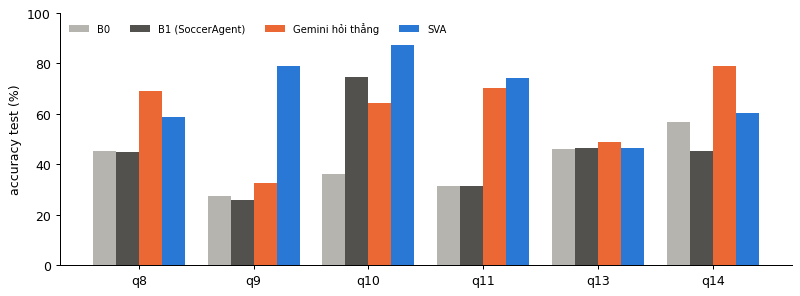

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(TASK_IDS)); w = 0.2
for j, (n, c) in enumerate([("B0", GRAY), ("B1 (SoccerAgent)", "#52514e"), ("Gemini hỏi thẳng", ORANGE), ("SVA", BLUE)]):
    ax.bar(x + (j - 1.5) * w, [100 * accuracy(P[n][t]) for t in TASK_IDS], w, color=c, label=n)
ax.set_xticks(x, TASK_IDS); ax.set_ylabel("accuracy test (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### 4.1 Kiểm tra chuỗi bằng chứng

In [29]:
rows = []
for t in TASK_IDS:
    recs = P["SVA"][t]
    bad_sum = sum(any(abs(sum(e["dist"].values()) - 1) > 1e-6 or set(e["dist"]) != set(e["option_keys"]) for e in r["evidence"])
                  for r in recs)
    rows.append({"task": t, "n": len(recs), "nhánh": recs[0]["branch"],
                 "câu không có bằng chứng": sum(not r["evidence"] for r in recs),
                 "bằng chứng lỗi (failed)": sum(e["failed"] for r in recs for e in r["evidence"]),
                 "dist không hợp lệ": bad_sum,
                 "pred ≠ argmax dist": sum(r["pred"] != max(r["dist"], key=r["dist"].get) for r in recs),
                 "câu lỗi khi chạy": sum("error" in r for r in recs),
                 "câu Reasoner hỏi thêm (%)": 100 * np.mean([len(r["steps"]) > 1 for r in recs])})
pd.DataFrame(rows).set_index("task")

,n,nhánh,câu không có bằng chứng,bằng chứng lỗi (failed),dist không hợp lệ,pred ≠ argmax dist,câu lỗi khi chạy,câu Reasoner hỏi thêm (%)
task,,,,,,,,
q8,280,B,0,0,0,0,0,38.571429
q9,280,C,0,0,0,0,0,0.000000
q10,700,A,0,0,0,0,0,0.000000
q11,700,A,0,0,0,0,0,0.000000
q13,490,B,0,0,0,0,0,75.510204
q14,192,C,0,0,0,0,0,0.000000


In [30]:
# 10 cau ngau nhien de doc bang tay: chuoi bang chung tu nhanh -> Reasoner -> dap an
random.seed(0)
for t in TASK_IDS:
    for r in random.sample(P["SVA"][t], 2 if t in ("q8", "q14", "q10", "q11") else 1):
        print(f"[{t} #{r['index']}] nhánh {r['branch']} | đáp án {r['gold']} | SVA chọn {r['pred']} "
              f"(độ tin {r['confidence']:.2f}, dừng: {r['stop']})")
        for e in r["evidence"]:
            d = {k: round(v, 2) for k, v in e["dist"].items()}
            print(f"    {e['tool_name']:<18} {d}  {e['raw_observation'][:90]}")

[q8 #287] nhánh B | đáp án O2 | SVA chọn O1 (độ tin 0.29, dừng: du tin)
    holistic           {'O1': 0.19, 'O2': 0.32, 'O3': 0.09, 'O4': 0.4}  
    camera_switch      {'O1': 0.84, 'O2': 0.13, 'O3': 0.0, 'O4': 0.03}  dau: Close-up player or field referee 0.42 | cuoi: Main camera center 0.66
[q8 #310] nhánh B | đáp án O2 | SVA chọn O2 (độ tin 0.05, dừng: het luot)
    holistic           {'O1': 0.3, 'O2': 0.36, 'O3': 0.16, 'O4': 0.19}  
    camera_switch      {'O1': 0.45, 'O2': 0.43, 'O3': 0.0, 'O4': 0.12}  dau: Main camera center 0.58 | cuoi: Main camera center 0.56
    reorder            {'O4': 0.23, 'O3': 0.03, 'O2': 0.4, 'O1': 0.34}  
    pairwise           {'O1': 0.34, 'O2': 0.42, 'O3': 0.06, 'O4': 0.18}  O2 vs O1: 0.55 / 0.45
    more_frames        {'O1': 0.3, 'O2': 0.38, 'O3': 0.14, 'O4': 0.18}  
[q9 #30] nhánh C | đáp án O3 | SVA chọn O3 (độ tin 0.82, dừng: du tin)
    replay_match       {'O1': 0.07, 'O2': 0.02, 'O3': 0.9, 'O4': 0.02}  O1: 0.827 (lui 0.35) | O2: 0.813 (lui 0.30) 